# 4. The worst days: what went wrong, and why

An average hides the days that hurt. This takes the recommended forecast (day-1 equal blend) over every out-of-sample day, July 2025 to November 2026, ranks the worst days, and diagnoses each one. The write-up is [`worst_days_memo.md`](worst_days_memo.md).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import wind

DATA = "../data/wind"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
if not os.path.exists(f"{DATA}/wind_hourly.parquet"):
    raise SystemExit("Run the download first, from the repo root: EIA_API_KEY=... python -m src.wind_data")

INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.width", 160)

In [2]:
w = pd.read_parquet(f"{DATA}/wind_hourly.parquet")
P = pd.read_parquet(f"{DATA}/preds_hub.parquet")
local = wind.forecast_table(P, w)
print("MAE, all hours:", round(local["err"].abs().mean()))
print("day 2 for comparison:", round((local["blend_d2"] - local["wind_mw"]).abs().mean()))

daily_all, daily = wind.daily_errors(local)
daily_all.sort_values("mae", ascending=False).head(3).round(0)

MAE, all hours: 1670
day 2 for comparison: 1846


,hours,mae,bias,actual,forecast
2025-12-05,1,11186.0,-11186.0,20336.0,10297.0
2026-03-14,24,5301.0,-5301.0,18258.0,12957.0
2026-01-24,24,4804.0,4804.0,12247.0,17051.0


The top "worst day" (5 Dec 2025) has **one hour**. EIA's wind actuals are missing for the next 24 hours, so that day can't be scored. From here on, only days with at least 20 hours count.

In [3]:
s = daily["mae"].sort_values(ascending=False)
print(f"{len(s)} full days; the worst 10% carry {s.head(len(s) // 10).sum() / s.sum():.0%} of all error")
worst = s.head(10).index
diag = pd.DataFrame({day: wind.diagnose(local, day) for day in worst}).T
diag.round(2)

495 full days; the worst 10% carry 19% of all error


,mae,bias,bias GFS,bias ICON,bias ECMWF,all same sign,mae d2,best shift (h),mae at best shift,forecast wind (m/s),wind percentile
2026-03-14,5300.67009,-5300.67009,-4275.335263,-5518.110369,-6108.564638,True,3611.93404,-3,4534.2721,7.329298,0.499448
2026-01-24,4803.707452,4803.707452,5632.724229,4781.757437,3996.64069,True,4538.679605,-6,4149.036411,7.952801,0.623769
2026-03-01,4463.464206,-4463.464206,-3137.771639,-4305.717355,-5946.903625,True,2253.65602,-2,4016.847233,7.46537,0.523465
2025-12-04,4205.549991,-3354.74676,-3094.086759,-3795.669772,-3174.48375,True,3752.248712,2,3609.127473,6.225625,0.336238
2026-10-04,4155.805718,4155.805718,3524.841076,4200.66194,4741.914138,True,2878.307595,6,3825.928821,5.984522,0.289131
2026-06-19,3832.289246,-287.558645,512.240123,-229.27823,-1145.637827,False,3656.96138,3,3210.543434,6.771921,0.41346
2025-12-12,3806.45999,-404.446551,-64.773538,-661.770595,-486.795519,True,3867.485741,4,2796.288624,7.204491,0.489082
2026-02-13,3782.254574,-3782.254574,-3177.678113,-4084.057434,-4085.028175,True,4664.22523,0,3782.254574,6.931644,0.445138
2026-08-08,3743.609624,-3583.813404,-3996.190958,-2986.95773,-3768.291524,True,3408.396776,1,3588.563261,6.25409,0.348082
2026-10-02,3649.089341,3510.166726,4560.553486,3371.639006,2598.307685,True,2371.20186,-2,3035.067557,7.923642,0.610163


**Reading it:**
- **All three providers missed in the same direction on 9 of 10 days.** These are shared weather misses, which blending can't fix.
- **Under-forecasts on windy days are the biggest group,** and on those days the *forecast* winds were ordinary (34th-52nd percentile). The weather models called for an ordinary day.
- **Timing:** on 12 Dec 2025 and 19 Jun 2026, moving the forecast 3-4 hours later cuts the error a lot. Right amount, wrong hours.
- **Day 2 looks better on most of these days, but that's selection bias.** These days were picked because day 1 failed; over all days, day 1 is clearly better.

**Was the power model the problem?** If it squashed strong forecast winds, it would show up at every wind level:

In [4]:
local["wind bin"] = pd.cut(local["ws_fc"], [0, 4, 6, 8, 10, 12, 14, 20])
pm = local.groupby("wind bin", observed=True)[["wind_mw", "blend_d1"]].mean()
pm["forecast vs actual (%)"] = 100 * (pm["blend_d1"] / pm["wind_mw"] - 1)
pm.round(1)

,wind_mw,blend_d1,forecast vs actual (%)
wind bin,,,
"(0, 4]",2614.5,2122.4,-18.8
"(4, 6]",6179.1,6043.9,-2.2
"(6, 8]",11910.8,11601.7,-2.6
"(8, 10]",18277.5,17729.0,-3.0
"(10, 12]",23451.4,22526.4,-3.9
"(12, 14]",25200.8,24836.5,-1.4
"(14, 20]",23055.6,23834.9,3.4


Above 4 m/s, the power model is within 1-4% of actual output at every level, running slightly low, consistent with fleet growth. So the bad days come from the weather input, not the power model.

**Two examples:** 24 Jan 2026 (Winter Storm Fern: ERCOT reports about 13.5 GW of wind capacity unavailable due to icing) and 12 Dec 2025 (a timing miss).

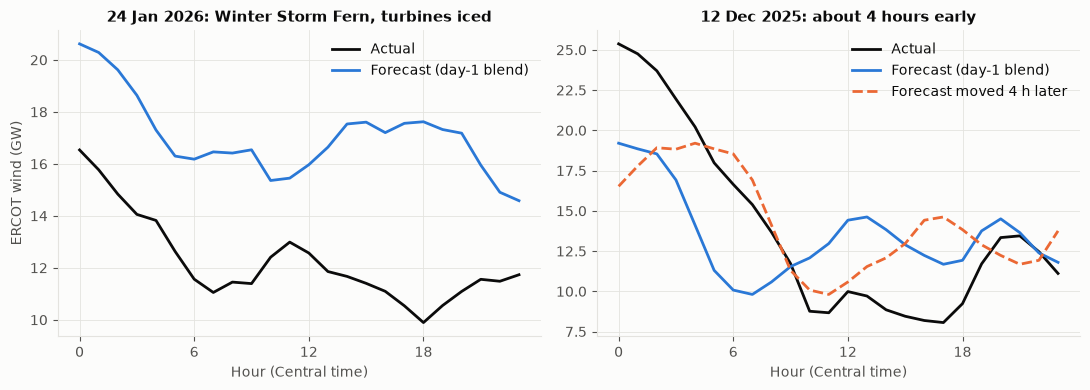

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, day, title in [(axes[0], "2026-01-24", "24 Jan 2026: Winter Storm Fern, turbines iced"),
                       (axes[1], "2025-12-12", "12 Dec 2025: about 4 hours early")]:
    g = local.loc[day]
    hrs = g.index.hour
    ax.plot(hrs, g["wind_mw"] / 1000, color=INK, lw=2, label="Actual")
    ax.plot(hrs, g["blend_d1"] / 1000, color=BLUE, lw=2, label="Forecast (day-1 blend)")
    if day == "2025-12-12":
        shifted = local["blend_d1"].shift(4).loc[day]
        ax.plot(hrs, shifted / 1000, color=ORANGE, lw=2, ls="--", label="Forecast moved 4 h later")
    ax.set_title(title)
    ax.set_xlabel("Hour (Central time)")
    ax.set_xticks(range(0, 24, 6))
    ax.legend(loc="best")
axes[0].set_ylabel("ERCOT wind (GW)")
fig.tight_layout()
fig.savefig(f"{FIG}/worst_day_examples.png", dpi=150)
plt.show()